---
title: "Control"
---

## Longitudinal control

### Automatic emergency braking (AEB)
We can reconstruct the target velocity using:
$$
v_{target} = v_i + \dot{d_i}
$$

This cannot be done for the acceleration of the target. That is why it uses a kalman filter (state observer) to estimate the accelration. This is based on the following assumptions:
- between the samples which are taken with $T_s$ the acceleration is assumed to be constant
- any real changes in acceleration are treated as process white noise $w_k$ acting on the system. Sensor inaccuracies are represented by measurement white noise $v_k$.


This results in the following equations.

State equation
$$x_{k+1} = A x_k + B u_k + G w_k$$

Measurement equation
$$y_k = C x_k + D u_k + v_k$$

With
$$
x_k = \begin{bmatrix} d_i \\ v_{target} \\ a_{target} \end{bmatrix} \qquad
A_k = \begin{bmatrix} 1 & T_s & \frac{T_s^2}{2} \\ 0 & 1 & T_s \\ 0 & 0 & 1 \end{bmatrix} \qquad
u_k = \begin{bmatrix} v_i \\ 0 \\ 0 \end{bmatrix} \qquad
y_k = \begin{bmatrix} d_i \\ \dot{d}_i \end{bmatrix}
$$

State estimate is then: 

$$\tilde{x}_{k+1} = A\tilde{x}_k + Bu_k + L(y_k - C\tilde{x}_k - Du_k)$$

This now results in various delays. The first delay is due to the kalman filter. Afterwards it takes time to apply the brakes. To mitigate the delays we can predict where the vehicle will be in $\Delta t$ seconds in the future. 

Prediction of host velocity
$$\bar{v}_i = v_i + \Delta t a_i$$

Prediction of target velocity
$$\bar{v}_t = v_t + \Delta t a_t$$

Prediction range
$$\bar{d}_i = \tilde{d}_i + (v_t - v_i)\Delta t + \frac{(a_t - a_i)\Delta t^2}{2}$$

Relative velocity:
$$(v_t - v_i) + (a_t - a_i)t_f = 0$$

This gives us
$$t_f = -\frac{v_t - v_i}{a_t - a_i}$$

Relative distance:
$$d_i + (v_t - v_i)t_f + \frac{(a_t - a_i)t_f^2}{2} = 0$$

Filling $t_1$ gives us the required host acceleration
$$a_i = a_t - \frac{(v_t - v_i)^2}{2d_i}$$

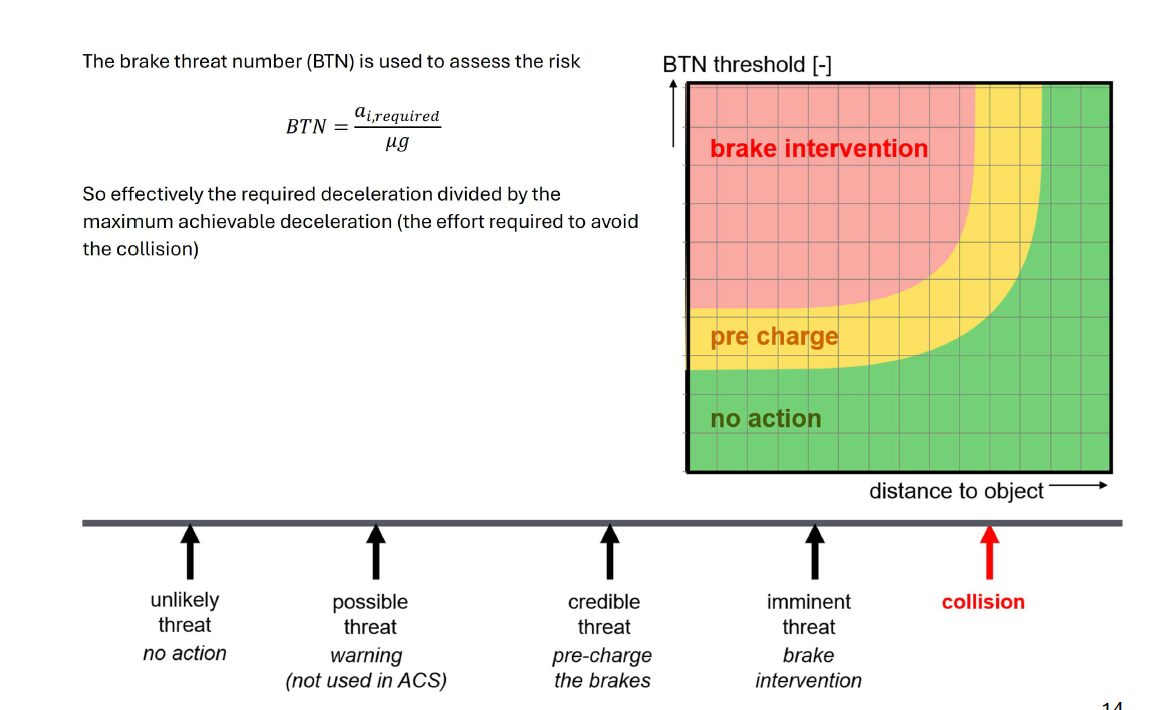

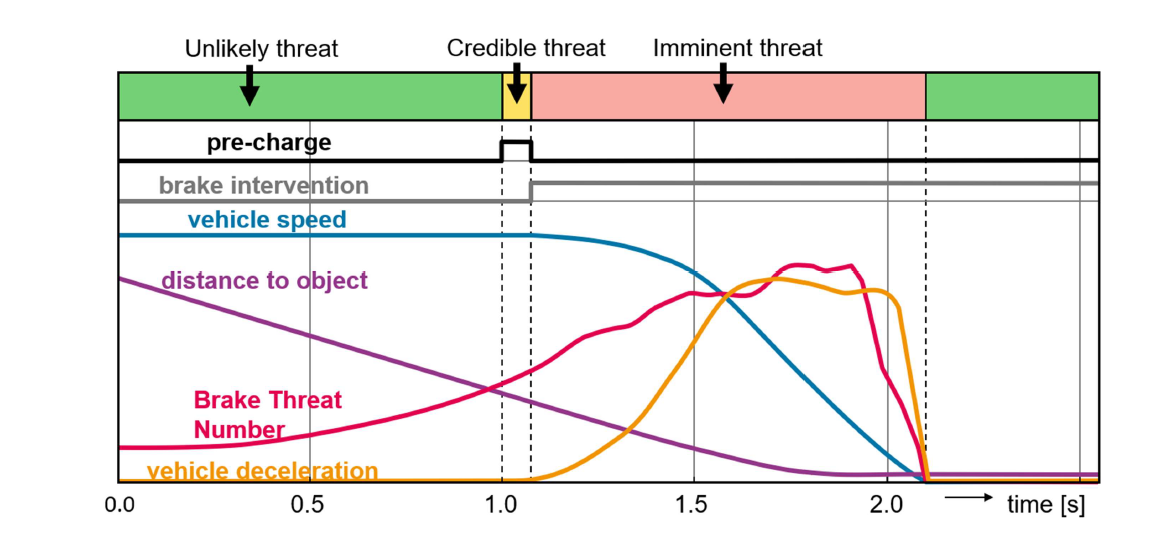

### Longitudinal control objectives for ACC
The desired vehcile following distance is $d_r = r + h \cdot v_i$, in which $h# is the headway time. Typically $d_i>d_r$ for safety. For comfort you want to limit $a_i$ and $\dot{a_i}$ and it must also satisfy speed limits therefore $v_i \le v_{max}$

so we need a vehicle model which takes int o account:
- drive force (non-linear)
- Aerodynamic drag (quadratic with speed)
$$
\begin{aligned}
F_{air} &= \frac{1}{2}\rho c_wA(v_x-v_w)^2\\
\rho &\approx 1.25 kg/m^3\\
c_wA &\approx 0.64 m^2 \\
\end{aligned}
$$ 
- Rolling resistance (constant) and drag forces
$$
\begin{aligned}
F_r &= f_rmg + k_{lin}v_x\\
f_r &\approx 0.0125\\
k_{lin} &\approx 2. Ns/m\\
\end{aligned}
$$


The total force equation therefore becomes:
$$
\begin{aligned}
m_{eff} a_x = & -mgf_r - k_{lin}v_x \\
& - \frac{1}{2}\rho c_w A(v_x - v_w)^2
\end{aligned}
$$
In what $m_{eff}$ is the effective mass of the car. However what is actually $m_{eff}$?
$$
\begin{aligned}
E_{kin} &= \frac{1}{2}mv_x^2 + \frac{4}{2}I_w \omega_w^2 + i^2 I_{motor}\omega_w^2 \\
&= \frac{1}{2}\underbrace{\left( m + \frac{4I_w}{r_w^2} + \frac{i^2 I_{motor}}{r_w^2} \right)}_{m_{eff}} v_x^2 \\
&= \frac{1}{2}m_{eff} v_x^2
\end{aligned}
$$